# 10 – Export für die Arbeit: Abbildungen (Kapitel 4) und Anhang-Tabellen

Dieses Notebook **rechnet nichts Neues**. Es führt die fertigen Notebooks 05–09 unverändert aus (`%run`), nimmt die dort geschätzten Objekte (Modelle, Vorhersagen, SHAP-Werte, Robustheits-Ergebnisse, Watchlist) und schreibt daraus:

- Abbildungen als PNG (300 dpi, englische Beschriftung, kein Titel im Bild) nach `thesis_figures/`
- Anhang-Tabellen als CSV und Markdown nach `thesis_tables/`

`%%capture` unterdrückt nur die Ausgaben der ausgeführten Notebooks, damit dieses Notebook übersichtlich bleibt. Daten und Pipeline werden nicht verändert (Notebooks 05–09 lesen nur; Notebook 04, das `model_data_palepu.csv` schreibt, wird **nicht** ausgeführt). Notebook 09 fragt dabei die SEC-EDGAR-Einreichungslisten erneut ab (nur lesend), genau wie im Notebook selbst.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("..") / "thesis_figures"
TAB = Path("..") / "thesis_tables"
FIG.mkdir(exist_ok=True)
TAB.mkdir(exist_ok=True)

# Einheitlicher Stil für alle Abbildungen: schlicht, gut lesbar im Druck
plt.rcParams.update({"font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300, "savefig.bbox": "tight", "figure.dpi": 100})
C_BLUE, C_ORANGE, C_GRAY, C_GRID, C_INK = "#2a78d6", "#eb6834", "#8a8984", "#e5e5e5", "#333333"

def md_table(df):
    """DataFrame -> Markdown-Tabelle (ohne Zusatzpaket)."""
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join("" if (not isinstance(v, str) and pd.isna(v)) else str(v) for v in r) + " |")
    return "\n".join(lines)

def write_table(df, name, title, notes=(), md_df=None):
    """Speichert die Tabelle als CSV (volle Genauigkeit) und als Markdown (gerundet, mit Titel und Anmerkungen)."""
    df.to_csv(TAB / f"{name}.csv", index=False)
    text = f"# {title}\n\n" + md_table(md_df if md_df is not None else df)
    if notes:
        text += "\n\n" + "\n".join(f"- {n}" for n in notes)
    (TAB / f"{name}.md").write_text(text + "\n", encoding="utf-8")
    print(f"geschrieben: thesis_tables/{name}.csv und .md ({len(df)} Zeilen)")

def save_fig(fig, name):
    fig.savefig(FIG / name)
    plt.show()
    print(f"geschrieben: thesis_figures/{name}")

fmt_p = lambda p: f"{p:.4f}" if p >= 0.0001 else "<0.0001"

# Lesbare Variablennamen für Abbildungen und Anhang-Tabellen (Code-Namen bleiben in den CSV-Dateien erhalten).
# interest_coverage_missing = 1 heißt NICHT nur "kein Zinsaufwand": Im Training sind es 41 % ohne Zinsaufwand,
# 29 % Zinsdaten fehlen trotz Schulden, 29 % Zinsaufwand vorhanden, aber operatives Ergebnis fehlt
# (src/15_compute_ratios.py). Deshalb das neutrale Label "Interest coverage not available".
LABELS = {
    "const": "Constant", "roe": "Return on equity", "sales_growth_1y": "Sales growth (1y)", "liquidity": "Liquidity",
    "leverage": "Leverage", "grdummy": "Growth–resource imbalance", "idummy": "Industry PE activity",
    "log_assets": "Log total assets", "log_assets_c": "Log total assets (centred)",
    "log_assets_c2": "Log total assets (centred)²", "float_to_book": "Float / book", "float_to_earnings": "Float / earnings",
    "fcf_to_assets": "Free cash flow / assets", "fcf_vol": "Cash flow volatility", "interest_coverage": "Interest coverage",
    "ppe_to_assets": "PP&E / assets", "rd_to_assets": "R&D / assets", "cash_ratio": "Cash ratio",
    "altman_z2": "Altman Z''-score", "roa": "Return on assets", "log_float": "Log public float",
    "grd_type1": "Imbalance type 1 (low growth, high liquidity, low leverage)",
    "grd_type2": "Imbalance type 2 (high growth, low liquidity, high leverage)",
    "roe_missing": "ROE not available", "sales_growth_1y_missing": "Sales growth not available",
    "liquidity_missing": "Liquidity not available", "grdummy_missing": "Growth–resource imbalance not available",
    "float_to_book_missing": "Float/book not available", "float_to_earnings_missing": "Float/earnings not available",
    "fcf_to_assets_missing": "Free cash flow not available", "interest_coverage_missing": "Interest coverage not available",
    "altman_z2_missing": "Altman Z''-score not available",
    "no_interest_expense": "No interest expense", "coverage_missing_other": "Interest coverage missing, other reason",
}
vlabel = lambda c: LABELS.get(c, c)

## Abb. 4.1 – Positive Firmenjahre pro Geschäftsjahr

Direkt aus `model_data_palepu.csv` (Stichprobe aus 02, 33.428 Zeilen, 282 Positive). Hinterlegt sind die drei Zeitabschnitte Training, Embargo und Test.

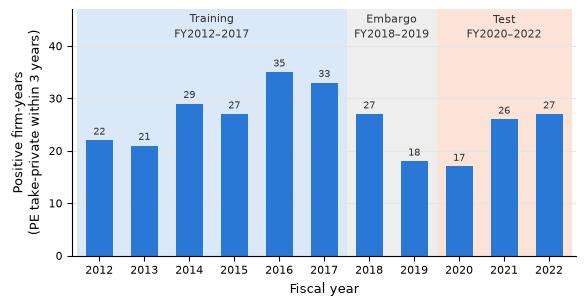

geschrieben: thesis_figures/fig4_1_positives_per_year.png
Minimum 17 (FY2020), Maximum 35 (FY2016)


fiscal_year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
rows,2948.000000,3059.000000,3179.000000,3114.000000,2849.000000,2909.000000,2940.000000,2834.000000,2935.000000,3484.000000,3177.000000
positives,22.000000,21.000000,29.000000,27.000000,35.000000,33.000000,27.000000,18.000000,17.000000,26.000000,27.000000
share,0.007463,0.006865,0.009122,0.008671,0.012285,0.011344,0.009184,0.006351,0.005792,0.007463,0.008499


In [2]:
Y = "y_pe_main_h3"
data_final = pd.read_csv(Path("..") / "data" / "processed" / "model_data_palepu.csv", dtype={"cik": str})
assert len(data_final) == 33_428 and data_final[Y].sum() == 282
per_year = data_final.groupby("fiscal_year").agg(rows=(Y, "size"), positives=(Y, "sum"))
per_year["share"] = per_year["positives"] / per_year["rows"]

fig, ax = plt.subplots(figsize=(6.5, 3.2))
periods = [(2012, 2017, "Training\nFY2012–2017", "#dbe8f8"), (2018, 2019, "Embargo\nFY2018–2019", "#eeeeee"),
           (2020, 2022, "Test\nFY2020–2022", "#fbe3d8")]
for a, b, label, color in periods:
    ax.axvspan(a - 0.5, b + 0.5, color=color, zorder=0, linewidth=0)
    ax.text((a + b) / 2, 46.5, label, ha="center", va="top", fontsize=8, color=C_INK, linespacing=1.3)
ax.bar(per_year.index, per_year["positives"], width=0.6, color=C_BLUE, zorder=2)
for yr, n in per_year["positives"].items():
    ax.text(yr, n + 0.6, f"{n}", ha="center", va="bottom", fontsize=7.5, color=C_INK)
ax.set_xticks(per_year.index, [str(y) for y in per_year.index])
ax.set_xlim(2011.4, 2022.6)
ax.set_ylim(0, 47)
ax.set_yticks(range(0, 41, 10))
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Positive firm-years\n(PE take-private within 3 years)")
ax.grid(axis="y", color=C_GRID, linewidth=0.8, zorder=1)
save_fig(fig, "fig4_1_positives_per_year.png")
print(f"Minimum {per_year['positives'].min()} (FY{per_year['positives'].idxmin()}), "
      f"Maximum {per_year['positives'].max()} (FY{per_year['positives'].idxmax()})")
per_year.T

## Notebook 05 ausführen (Modell A und Variante A2)

In [3]:
%%capture
%run "05_palepu_logit.ipynb"

In [4]:
# Objekte aus 05 sichern, bevor das nächste Notebook gleichnamige Variablen überschreibt
A = {"res": result, "train": train, "test_y": test[Y].to_numpy(), "test_p": test["p_hat"].to_numpy()}
A2 = {"res": result_a2, "train": train_a2}
print(f"Modell A: McFadden {A['res'].prsquared:.2%} | Test-ROC-AUC {roc_auc_score(A['test_y'], A['test_p']):.3f}")
print(f"Variante A2: McFadden {A2['res'].prsquared:.2%}")

Modell A: McFadden 2.03% | Test-ROC-AUC 0.634
Variante A2: McFadden 2.10%


## Notebook 06 ausführen (Modell B und Variante B2)

In [5]:
%%capture
%run "06_extended_logit.ipynb"

In [6]:
B = {"res": res_b, "train": tr, "test_y": te[Y].to_numpy(), "test_p": te["p_b"].to_numpy(), "cols": B_COLS}
B2 = {"res": res_b2, "train": tr, "cols": B2_COLS, "size_mean": size_mean, "vertex_c": vertex_c}
spear_06 = spear                     # Spearman-Matrix aus 06 (für die Variablendefinitionen)
assert abs(res_a.prsquared - A["res"].prsquared) < 1e-12   # A in 06 identisch mit A in 05
print(f"Modell B: McFadden {B['res'].prsquared:.2%} | Test-ROC-AUC {roc_auc_score(B['test_y'], B['test_p']):.3f}")
print(f"Variante B2: McFadden {B2['res'].prsquared:.2%}")

Modell B: McFadden 4.55% | Test-ROC-AUC 0.698
Variante B2: McFadden 5.43%


## Abb. 4.2 – Größeneffekt in Variante B2

Gleiche Rechnung wie in 06, Abschnitt 8: vorhergesagte Wahrscheinlichkeit über der Bilanzsumme (von 10 Mio. USD, der Schwelle aus Robustheitscheck 5, bis P99 des Trainings), alle übrigen Variablen auf dem Trainingsmedian; das 95 %-Band nutzt die nach Firma geclusterte Kovarianzmatrix. Der Scheitelpunkt und sein Intervall (Delta-Methode) stehen in der Beschriftung.

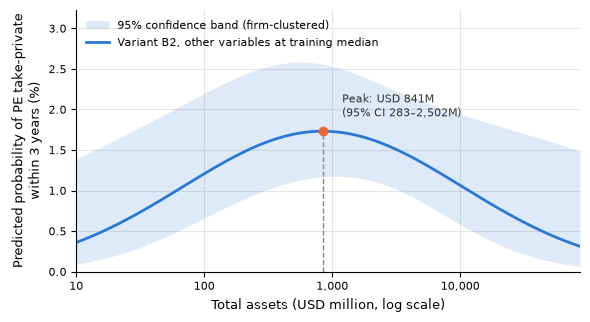

geschrieben: thesis_figures/fig4_2_size_effect_B2.png
Scheitelpunkt 841 Mio. USD (95 %-KI 283–2,502); Wahrscheinlichkeit dort 1.73%
x-Bereich: 10 Mio. USD (Schwelle wie Check 5) bis P99 der Bilanzsumme im Training 86,205 Mio. USD


Kontrolle Rohwerte Training: P1 0.009 | P5 9.0 | P95 24,884 | P99 86,700 Mio. USD


In [7]:
r2, cols2, tr2, m2 = B2["res"], B2["cols"], B2["train"], B2["size_mean"]
b1, b2q = r2.params["log_assets_c"], r2.params["log_assets_c2"]
vc = -b1 / (2 * b2q)
V = r2.cov_params().loc[["log_assets_c", "log_assets_c2"], ["log_assets_c", "log_assets_c2"]].to_numpy()
grad = np.array([-1 / (2 * b2q), b1 / (2 * b2q ** 2)])
se_v = np.sqrt(grad @ V @ grad)
musd = lambda c: np.exp(m2 + c) / 1e6
peak, peak_lo, peak_hi = musd(vc), musd(vc - 1.96 * se_v), musd(vc + 1.96 * se_v)

# x-Bereich: ab 10 Mio. USD Bilanzsumme (gleiche Schwelle wie Robustheitscheck 5) bis P99 des Trainings
grid = np.linspace(np.log(10e6) - m2, tr2["log_assets_c"].quantile(0.99), 300)
Xg = pd.DataFrame([tr2[cols2].median()] * len(grid))
Xg["log_assets_c"], Xg["log_assets_c2"] = grid, grid ** 2
Xg = sm.add_constant(Xg[cols2], has_constant="add").to_numpy()
eta = Xg @ r2.params.to_numpy()
se_eta = np.sqrt(np.einsum("ij,jk,ik->i", Xg, r2.cov_params().to_numpy(), Xg))
inv = lambda z: 1 / (1 + np.exp(-z))
x = musd(grid)
eta_peak = sm.add_constant(pd.DataFrame([tr2[cols2].median()]), has_constant="add")
eta_peak["log_assets_c"], eta_peak["log_assets_c2"] = vc, vc ** 2
p_peak = inv(eta_peak[["const"] + cols2].to_numpy() @ r2.params.to_numpy())[0]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.fill_between(x, 100 * inv(eta - 1.96 * se_eta), 100 * inv(eta + 1.96 * se_eta), color=C_BLUE, alpha=0.15,
                linewidth=0, label="95% confidence band (firm-clustered)")
ax.plot(x, 100 * inv(eta), color=C_BLUE, linewidth=2, label="Variant B2, other variables at training median")
ax.plot([peak, peak], [0, 100 * p_peak], color=C_GRAY, linestyle="--", linewidth=1)   # Linie nur bis zum Peak
ax.plot([peak], [100 * p_peak], "o", color=C_ORANGE, markersize=6, zorder=4)
ax.annotate(f"Peak: USD {peak:,.0f}M\n(95% CI {peak_lo:,.0f}–{peak_hi:,.0f}M)", (peak, 100 * p_peak),
            xytext=(14, 8), textcoords="offset points", fontsize=8, color=C_INK, va="bottom")
ax.set_xscale("log")
ax.set_xlim(x.min(), x.max())                     # Achse von 10 Mio. USD bis P99 des Trainings
ticks = [t for t in [0.1, 1, 10, 100, 1000, 10000, 100000] if x.min() * 0.999 <= t <= x.max()]
ax.set_xticks(ticks, [f"{t:,.1f}" if t < 1 else f"{t:,.0f}" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Total assets (USD million, log scale)")
ax.set_ylabel("Predicted probability of PE take-private\nwithin 3 years (%)")
ax.set_ylim(0, 100 * inv(eta + 1.96 * se_eta).max() * 1.25)    # Platz über dem Band für die Legende
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1f}"))
ax.legend(frameon=False, loc="upper left")
ax.grid(color=C_GRID, linewidth=0.8)
ax.set_axisbelow(True)
save_fig(fig, "fig4_2_size_effect_B2.png")
print(f"Scheitelpunkt {peak:,.0f} Mio. USD (95 %-KI {peak_lo:,.0f}–{peak_hi:,.0f}); Wahrscheinlichkeit dort {p_peak:.2%}")
print(f"x-Bereich: {x.min():,.0f} Mio. USD (Schwelle wie Check 5) bis P99 der Bilanzsumme im Training {x.max():,.0f} Mio. USD")
raw_ta = data_final[data_final["split"] == "train"][["accession"]].merge(
    pd.read_csv(Path("..") / "data" / "processed" / "firm_year_fundamentals.csv", usecols=["accession", "total_assets"]),
    on="accession")["total_assets"] / 1e6
print(f"Kontrolle Rohwerte Training: P1 {raw_ta.quantile(0.01):,.3f} | P5 {raw_ta.quantile(0.05):,.1f} | "
      f"P95 {raw_ta.quantile(0.95):,.0f} | P99 {raw_ta.quantile(0.99):,.0f} Mio. USD")

## Anhang: Koeffiziententabellen A, A2, B, B2

Koeffizient, Odds Ratio, nach Firma geclusterter Standardfehler und p-Wert, jeweils auf dem Training FY2012–2017. Dazu je Modell N, Positive, Firmen (Cluster), McFadden-Pseudo-R² und Log-Likelihood.

In [8]:
MODELS = {"Model A": A, "Variant A2": A2, "Model B": B, "Variant B2": B2}
coef_rows, fit_rows = [], []
for name, m in MODELS.items():
    r, d = m["res"], m["train"]
    for v in r.params.index:
        coef_rows.append({"model": name, "variable": vlabel(v), "code": v, "coefficient": r.params[v], "odds_ratio": np.exp(r.params[v]),
                          "se_clustered": r.bse[v], "z": r.tvalues[v], "p_value": r.pvalues[v]})
    fit_rows.append({"model": name, "N (firm-years)": int(r.nobs), "positives": int(d[Y].sum()),
                     "firms (clusters)": d["cik"].nunique(), "parameters incl. constant": len(r.params),
                     "McFadden pseudo-R2": r.prsquared, "log-likelihood": r.llf, "log-likelihood (constant only)": r.llnull,
                     "LR chi2": r.llr, "LR p-value": r.llr_pvalue})
coefs, fits = pd.DataFrame(coef_rows), pd.DataFrame(fit_rows)

notes = ["Estimation sample: training period FY2012–2017; outcome y_pe_main_h3 (PE take-private within 3 years).",
         "Unpenalised, unweighted logit (statsmodels, Newton); standard errors clustered by firm (CIK).",
         "Continuous variables winsorised at the training P1/P99 and median-imputed; *_missing = 1 if the raw value was missing.",
         "B2: log_assets centred at the training mean (log_assets_c) plus its square (log_assets_c2)."]
md_coefs = []
for name in MODELS:
    t = coefs[coefs["model"] == name].drop(columns="code")
    t["p_value"] = t["p_value"].map(fmt_p)
    for c in ["coefficient", "odds_ratio", "se_clustered", "z"]:
        t[c] = t[c].map(lambda v: f"{v:.4f}")
    md_coefs.append(t)
write_table(coefs, "appendix_coefficients", "Logit coefficient tables: Models A, A2, B and B2", notes,
            md_df=pd.concat(md_coefs))
fits_md = fits.copy()
fits_md["McFadden pseudo-R2"] = fits_md["McFadden pseudo-R2"].map(lambda v: f"{v:.2%}")
for c in ["log-likelihood", "log-likelihood (constant only)", "LR chi2"]:
    fits_md[c] = fits_md[c].map(lambda v: f"{v:.1f}")
fits_md["LR p-value"] = fits_md["LR p-value"].map(fmt_p)
write_table(fits, "appendix_model_fit", "Model fit statistics (training FY2012–2017)", notes[:2], md_df=fits_md)
fits_md

geschrieben: thesis_tables/appendix_coefficients.csv und .md (86 Zeilen)
geschrieben: thesis_tables/appendix_model_fit.csv und .md (4 Zeilen)


,model,N (firm-years),positives,firms (clusters),parameters incl. constant,McFadden pseudo-R2,log-likelihood,log-likelihood (constant only),LR chi2,LR p-value
0,Model A,18058,167,4763,16,2.03%,-929.1,-948.3,38.5,0.0008
1,Variant A2,18058,167,4763,17,2.10%,-928.4,-948.3,39.8,0.0008
2,Model B,18058,167,4763,26,4.55%,-905.2,-948.3,86.3,<0.0001
3,Variant B2,18058,167,4763,27,5.43%,-896.9,-948.3,102.9,<0.0001


## Anhang: Variablendefinitionen

Formel und XBRL-Quelle laut Pipeline (`src/14_build_fundamentals.py`, `src/13c_debt_three_state.py`, `src/15_compute_ratios.py`, `docs/data_dictionary.md`). **% fehlend** = Anteil der Trainingszeilen (FY2012–2017, 18.058 Zeilen) ohne Rohwert, also **vor** dem Auffüllen. Die Behandlung folgt den Entscheidungen in `PROGRESS.md`.

In [9]:
DATA = Path("..") / "data"
raw = (data_final[data_final["split"] == "train"][["accession", "sic", "y_pe_main_h3", "grdummy_missing"]]
       .merge(pd.read_csv(DATA / "processed" / "firm_year_ratios.csv",
                          usecols=["accession", "sales_growth_1y", "leverage", "log_assets", "float_to_book", "float_to_earnings",
                                   "fcf_to_assets", "fcf_vol", "interest_coverage", "ppe_to_assets", "rd_to_assets",
                                   "cash_ratio", "altman_z2", "roa", "log_float", "no_interest_expense",
                                   "interest_data_missing"]), on="accession", validate="one_to_one")
       .merge(pd.read_csv(DATA / "processed" / "firm_year_fundamentals.csv",
                          usecols=["accession", "net_income", "equity", "cash", "liabilities_current", "total_assets"]),
              on="accession", validate="one_to_one"))
raw["roe"] = raw["net_income"] / raw["equity"].where(raw["equity"] > 0)
raw["liquidity"] = (raw["cash"] - raw["liabilities_current"]) / raw["total_assets"].where(raw["total_assets"] > 0)
assert len(raw) == 18_058

# Was bedeutet interest_coverage_missing = 1? Aufteilung der fehlenden Werte im Training (Flags aus src/15)
icm = raw["interest_coverage"].isna()
ic_no_interest = raw.loc[icm, "no_interest_expense"].mean()
ic_data_gap = raw.loc[icm, "interest_data_missing"].mean()
ic_no_opinc = 1 - ic_no_interest - ic_data_gap               # Zinsaufwand > 0, aber operatives Ergebnis fehlt
print(f"interest_coverage fehlt in {icm.sum():,} Trainingszeilen: kein Zinsaufwand {ic_no_interest:.1%} | "
      f"Zinsdaten fehlen trotz Schulden {ic_data_gap:.1%} | operatives Ergebnis fehlt {ic_no_opinc:.1%}")
missing_share = {v: raw[v].isna().mean() for v in ["roe", "sales_growth_1y", "liquidity", "leverage", "log_assets",
                                                   "float_to_book", "float_to_earnings", "fcf_to_assets", "fcf_vol",
                                                   "interest_coverage", "ppe_to_assets", "rd_to_assets", "cash_ratio",
                                                   "altman_z2", "roa", "log_float"]}
missing_share["grdummy"] = raw["grdummy_missing"].mean()
missing_share["idummy"] = pd.to_numeric(raw["sic"], errors="coerce").isna().mean()     # idummy fehlt nur ohne SIC

B_IND = [c for c in B["cols"] if c.endswith("_missing")]
TAGS = {
    "net_income": "NetIncomeLoss → ProfitLoss → NetIncomeLossAvailableToCommonStockholdersBasic",
    "equity": "StockholdersEquity → StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
    "total_assets": "Assets → LiabilitiesAndStockholdersEquity",
    "cash": "CashAndCashEquivalentsAtCarryingValue → CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalents → Cash → CashAndDueFromBanks → CashCashEquivalentsAndFederalFundsSold",
    "liabilities_current": "LiabilitiesCurrent",
    "revenue": "Revenues → RevenueFromContractWithCustomerExcludingAssessedTax → SalesRevenueNet → … (7 standard tags, then 13 industry tags; zero-filled if none)",
    "debt": "Debt waterfall (src/13c): DebtCurrent or current parts (LongTermDebtCurrent, ShortTermBorrowings, NotesPayableCurrent, …) + LongTermDebtNoncurrent or LongTermDebt or alternates (SeniorNotes, ConvertibleNotesPayable, LineOfCredit, …); LongTermDebtAndCapitalLeaseObligations as fallback; leases excluded",
    "float": "dei:EntityPublicFloat (frames API, Company Facts fallback)",
    "ocf": "NetCashProvidedByUsedInOperatingActivities → …ContinuingOperations",
    "capex": "PaymentsToAcquirePropertyPlantAndEquipment → PaymentsToAcquireProductiveAssets → PaymentsToAcquireOtherPropertyPlantAndEquipment (0 if no PP&E)",
    "op_income": "OperatingIncomeLoss",
    "interest": "InterestExpense → InterestExpenseDebt → InterestExpenseLongTermDebt → InterestExpenseNonoperating → InterestPaidNet → InterestPaid",
    "ppe": "PropertyPlantAndEquipmentNet → …AndFinanceLeaseRightOfUseAsset… → PublicUtilitiesPropertyPlantAndEquipmentNet → industry tags (zero-filled if none)",
    "rd": "ResearchAndDevelopmentExpense → …ExcludingAcquiredInProcessCost → …SoftwareExcludingAcquiredInProcessCost (zero-filled if none)",
    "re": "RetainedEarningsAccumulatedDeficit",
    "ac": "AssetsCurrent",
    "liab": "Liabilities (else total assets − equity)",
}
t = lambda *keys: "; ".join(f"{k.replace('_', ' ')}: {TAGS[k]}" for k in keys)
rho = lambda a, b: spear_06.loc[a, b]
DEFS = [
    # name, Gruppe, Formel, XBRL-Tags
    ("roe", "Palepu", "net income / stockholders' equity (missing if equity ≤ 0)", t("net_income", "equity")),
    ("sales_growth_1y", "Palepu", "revenue_t / revenue_(t−1) − 1 (only if both revenues are tagged)", t("revenue")),
    ("liquidity", "Palepu", "(cash − current liabilities) / total assets", t("cash", "liabilities_current", "total_assets")),
    ("leverage", "Palepu", "total debt / total assets (missing if debt only under dimension/custom tags)", t("debt", "total_assets")),
    ("grdummy", "Palepu", "1 if (low growth, high liquidity, low leverage) or (high growth, low liquidity, high leverage); high/low vs. the fiscal-year sample median", "derived from sales_growth_1y, liquidity, leverage"),
    ("idummy", "Palepu", "1 if ≥ 1 sponsor-like PE take-private (first event date) in the same 2-digit SIC in calendar year t−1", "SIC from EDGAR filing index; events from combined_events.csv"),
    ("log_assets", "Palepu", "ln(total assets); B2: centred at training mean (log_assets_c) plus square (log_assets_c2)", t("total_assets")),
    ("float_to_book", "Palepu", "public float / stockholders' equity", t("float", "equity")),
    ("float_to_earnings", "Palepu", "public float / net income", t("float", "net_income")),
    ("fcf_to_assets", "Model B", "(operating cash flow − capex) / total assets", t("ocf", "capex", "total_assets")),
    ("fcf_vol", "Model B", "std. dev. of fcf_to_assets over t, t−1, t−2 (two years if only two available)", t("ocf", "capex", "total_assets")),
    ("interest_coverage", "Model B", "operating income / interest expense (only if interest expense > 0)", t("op_income", "interest")),
    ("ppe_to_assets", "Model B", "net PP&E / total assets", t("ppe", "total_assets")),
    ("rd_to_assets", "Model B", "R&D expense / total assets", t("rd", "total_assets")),
    ("cash_ratio", "Model B", "cash / total assets", t("cash", "total_assets")),
    ("altman_z2", "Model B", "Altman Z'' = 6.56·X1 + 3.26·X2 + 6.72·X3 + 1.05·X4; X1 = (current assets − current liabilities)/assets, X2 = retained earnings/assets, X3 = operating income/assets, X4 = public float/total liabilities", t("ac", "liabilities_current", "re", "op_income", "float", "liab", "total_assets")),
    ("roa", "considered, not used", "net income / total assets", t("net_income", "total_assets")),
    ("log_float", "considered, not used", "ln(public float)", t("float")),
]
rows = []
for name, group, formula, tags in DEFS:
    if name == "grdummy":
        treat = "binary; set to 0 if an input is missing, plus indicator grdummy_missing"
    elif name == "idummy":
        treat = "binary; median-imputed if SIC missing; no indicator (rule not met)"
    elif name == "roa":
        treat = f"not in Model B: Spearman rho = {rho('roa', 'roe'):.2f} with roe (> 0.7)"
    elif name == "log_float":
        treat = f"not in Model B: Spearman rho = {rho('log_float', 'log_assets'):.2f} with log_assets (> 0.7)"
    else:
        ind = f"{name}_missing"
        treat = "winsorised P1/P99 (training); median-imputed; " + (
            f"indicator {ind}" if ind in B_IND else
            ("indicator dropped (Spearman rho > 0.7 with a Model A indicator)" if name == "fcf_vol" else "no indicator (rule not met)"))
    rows.append({"variable": vlabel(name), "code": name, "group": group, "formula": formula, "XBRL source tags (priority order)": tags,
                 "% missing in training (raw)": round(100 * missing_share[name], 1), "treatment": treat})
var_defs = pd.DataFrame(rows)
write_table(var_defs, "appendix_variable_definitions", "Variable definitions",
            ["All facts: annual, non-dimensional us-gaap facts from the SEC DERA financial statement data sets, dated at the 10-K period end; public float from dei:EntityPublicFloat.",
             "'→' = priority order: the first tag with a value is used.",
             "Indicator rule: keep <var>_missing only if > 2% of training rows are missing and ≥ 5 training positives fall in the gap; new indicators are dropped if Spearman |rho| > 0.7 with a Model A indicator.",
             "Winsorisation limits and imputation medians are computed on the training period FY2012–2017 only.",
             f"Missing-value indicators in Model B: {'; '.join(f'{vlabel(i)} ({i})' for i in B_IND)}.",
             f"Interest coverage not available (interest_coverage_missing = 1) covers three cases in training: no interest expense ({ic_no_interest:.0%}), interest expense untagged although the firm has debt ({ic_data_gap:.0%}), interest expense > 0 but operating income missing ({ic_no_opinc:.0%})."])
var_defs[["variable", "code", "% missing in training (raw)", "treatment"]]

interest_coverage fehlt in 5,717 Trainingszeilen: kein Zinsaufwand 41.2% | Zinsdaten fehlen trotz Schulden 29.4% | operatives Ergebnis fehlt 29.5%
geschrieben: thesis_tables/appendix_variable_definitions.csv und .md (18 Zeilen)


,variable,code,% missing in training (raw),treatment
0,Return on equity,roe,12.2,winsorised P1/P99 (training); median-imputed; ...
1,Sales growth (1y),sales_growth_1y,31.5,winsorised P1/P99 (training); median-imputed; ...
2,Liquidity,liquidity,12.2,winsorised P1/P99 (training); median-imputed; ...
3,Leverage,leverage,2.4,winsorised P1/P99 (training); median-imputed; ...
4,Growth–resource imbalance,grdummy,39.1,"binary; set to 0 if an input is missing, plus ..."
5,Industry PE activity,idummy,0.0,binary; median-imputed if SIC missing; no indi...
6,Log total assets,log_assets,0.9,winsorised P1/P99 (training); median-imputed; ...
7,Float / book,float_to_book,8.7,winsorised P1/P99 (training); median-imputed; ...
8,Float / earnings,float_to_earnings,6.1,winsorised P1/P99 (training); median-imputed; ...
9,Free cash flow / assets,fcf_to_assets,11.8,winsorised P1/P99 (training); median-imputed; ...


## Notebook 07 ausführen (Random Forest und XGBoost)

In [10]:
%%capture
%run "07_tree_models.ipynb"

In [11]:
C = {"rf": rf, "xgb": xgb, "test_y": te[Y].to_numpy(), "p_rf": te["p_rf"].to_numpy(), "p_xgb": te["p_xgb"].to_numpy(),
     "shap_rf": shap_rf, "shap_xgb": shap_xgb, "X_tr": X_tr, "grid_rf": grid_rf, "grid_xgb": grid_xgb,
     "rf_params": rf_params, "xgb_params": xgb_params, "base_ll": base_ll}
assert np.allclose(te["p_b"].to_numpy(), B["test_p"])      # Modell B in 07 identisch mit 06
for k in ["p_rf", "p_xgb"]:
    print(f"{k}: Test-ROC-AUC {roc_auc_score(C['test_y'], C[k]):.3f}")

p_rf: Test-ROC-AUC 0.656
p_xgb: Test-ROC-AUC 0.677


## Abb. 4.3 – Kalibrierung auf dem Test (A, B, RF, XGB)

Wie in den Notebooks: Testzeilen nach Vorhersage in 10 gleich große Gruppen; je Gruppe mittlere Vorhersage (x) gegen tatsächlichen Anteil der Ziele (y), beide in %. Gleiche Achsen in allen vier Feldern, damit die Modelle vergleichbar sind. Die Zahl neben jedem Punkt ist die Anzahl der Ziele in der Gruppe.

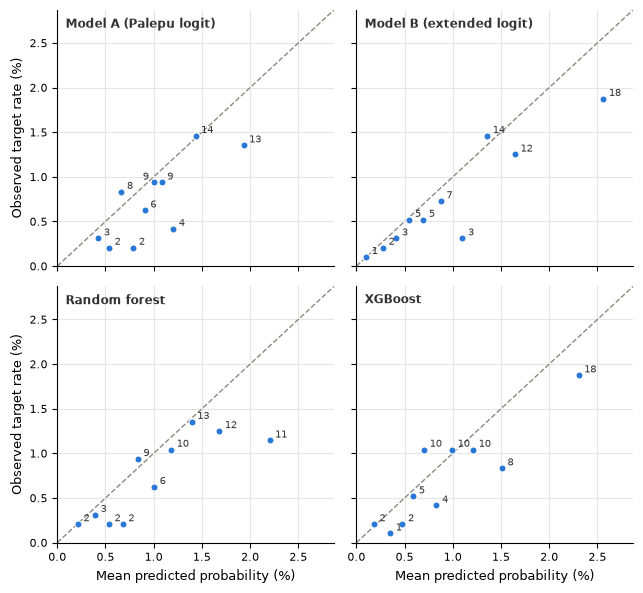

geschrieben: thesis_figures/fig4_3_calibration.png
geschrieben: thesis_tables/calibration_bins.csv und .md (40 Zeilen)


In [12]:
CAL_MODELS = [("Model A (Palepu logit)", A["test_y"], A["test_p"]), ("Model B (extended logit)", B["test_y"], B["test_p"]),
              ("Random forest", C["test_y"], C["p_rf"]), ("XGBoost", C["test_y"], C["p_xgb"])]
cal, cal_rows = {}, []
for name, y_, p_ in CAL_MODELS:
    d = pd.DataFrame({"p": p_, "y": y_})
    d["bin"] = pd.qcut(d["p"], 10, labels=False, duplicates="drop")
    c = d.groupby("bin").agg(predicted=("p", "mean"), observed=("y", "mean"), rows=("y", "size"), targets=("y", "sum"))
    cal[name] = c
    cal_rows += [{"model": name, "bin": int(b) + 1, **r} for b, r in c.to_dict("index").items()]
lim = 100 * max(max(c["predicted"].max(), c["observed"].max()) for c in cal.values()) * 1.12

fig, axes = plt.subplots(2, 2, figsize=(6.5, 6.0), sharex=True, sharey=True)
for ax, (name, c) in zip(axes.flat, cal.items()):
    ax.plot([0, lim], [0, lim], color=C_GRAY, linestyle="--", linewidth=1)
    ax.scatter(100 * c["predicted"], 100 * c["observed"], s=26, color=C_BLUE, edgecolor="white", linewidth=0.8, zorder=3)
    pts = list(zip(100 * c["predicted"], 100 * c["observed"], c["targets"].astype(int)))
    for px, py, n in pts:
        # Liegt direkt rechts daneben ein weiterer Punkt, kommt die Zahl links an den Punkt (sonst rechts)
        right_neighbour = any(0 < qx - px < 0.10 and abs(qy - py) < 0.05 for qx, qy, _ in pts)
        ax.annotate(f"{n}", (px, py), xytext=(-4, 2) if right_neighbour else (4, 2), textcoords="offset points",
                    ha="right" if right_neighbour else "left", fontsize=7, color=C_INK)
    ax.text(0.03, 0.97, name, transform=ax.transAxes, ha="left", va="top", fontsize=8.5, fontweight="bold", color=C_INK)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.grid(color=C_GRID, linewidth=0.8); ax.set_axisbelow(True)
for ax in axes[1]:
    ax.set_xlabel("Mean predicted probability (%)")
for ax in axes[:, 0]:
    ax.set_ylabel("Observed target rate (%)")
fig.tight_layout()
save_fig(fig, "fig4_3_calibration.png")
cal_table = pd.DataFrame(cal_rows)
write_table(cal_table, "calibration_bins", "Calibration on the test set (FY2020–2022): 10 equal-size bins per model",
            ["Data behind Figure 4.3. predicted = mean predicted 3-year probability in the bin; observed = share of targets."],
            md_df=cal_table.assign(predicted=lambda d: (100 * d["predicted"]).map("{:.2f}%".format),
                                   observed=lambda d: (100 * d["observed"]).map("{:.2f}%".format)))

## Abb. 4.4 – SHAP-Summary (XGBoost und Random Forest, Training)

Dieselben SHAP-Werte wie in 07 (TreeExplainer auf dem ganzen Training). XGBoost-Werte sind in Log-Odds, Random-Forest-Werte in Wahrscheinlichkeit (für lesbare Achsen in Prozentpunkten dargestellt); vergleichbar ist deshalb die Rangfolge, nicht die Größe.

/var/folders/31/3k2r2ymj5rsdx51ck0lq0wfw0000gn/T/ipykernel_31618/602112094.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(vals, C["X_tr"], feature_names=[vlabel(f) for f in C["X_tr"].columns], max_display=12,
/var/folders/31/3k2r2ymj5rsdx51ck0lq0wfw0000gn/T/ipykernel_31618/602112094.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(vals, C["X_tr"], feature_names=[vlabel(f) for f in C["X_tr"].columns], max_display=12,


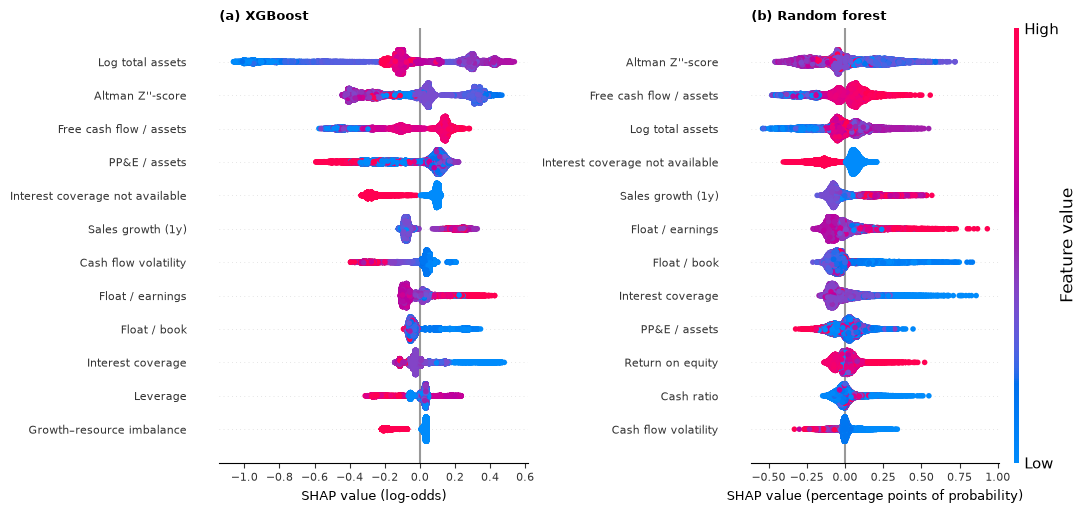

geschrieben: thesis_figures/fig4_4_shap_summary.png


In [13]:
import shap

fig = plt.figure(figsize=(11, 5.2))
for i, (vals, label, unit) in enumerate([(C["shap_xgb"], "(a) XGBoost", "SHAP value (log-odds)"),
                                         (100 * C["shap_rf"], "(b) Random forest", "SHAP value (percentage points of probability)")]):
    ax = fig.add_subplot(1, 2, i + 1)
    np.random.seed(20261030)          # summary_plot mischt die Punkte zufällig -> fester Startwert, damit die PNG gleich bleibt
    shap.summary_plot(vals, C["X_tr"], feature_names=[vlabel(f) for f in C["X_tr"].columns], max_display=12,
                      show=False, plot_size=None, color_bar=(i == 1))
    ax.set_xlabel(unit, fontsize=9)
    ax.set_title(label, loc="left", fontsize=9, fontweight="bold")
    ax.tick_params(labelsize=8)
fig.tight_layout()
save_fig(fig, "fig4_4_shap_summary.png")

## Anhang: Hyperparameter-Grids (RF und XGBoost)

Fit FY2012–2015, Validierung FY2016–2017, Kriterium Log-Loss (wie in 07). Die gewählte Kombination ist markiert; danach wurde mit ihr auf dem ganzen Training neu gefittet.

In [14]:
rf_g = C["grid_rf"].copy()
rf_g.insert(0, "model", "Random forest")
rf_g["max_depth"] = rf_g["max_depth"].map(lambda v: "None (unlimited)" if pd.isna(v) else int(v))
xgb_g = C["grid_xgb"].copy()
xgb_g.insert(0, "model", "XGBoost")
for g, best in [(rf_g, C["rf_params"]), (xgb_g, C["xgb_params"])]:
    g["chosen"] = ["yes" if i == 0 else "" for i in range(len(g))]      # Grid ist nach Log-Loss sortiert
hyper = pd.concat([rf_g, xgb_g], ignore_index=True)
hyper = hyper.rename(columns={"Log-Loss (Validierung)": "validation log-loss", "ROC-AUC (Validierung, nur Info)": "validation ROC-AUC (info only)"})
cols_order = ["model", "max_depth", "min_samples_leaf", "learning_rate", "n_estimators", "validation log-loss",
              "validation ROC-AUC (info only)", "chosen"]
hyper = hyper[cols_order]
hyper_md = hyper.copy()
hyper_md["validation log-loss"] = hyper_md["validation log-loss"].map("{:.5f}".format)
hyper_md["validation ROC-AUC (info only)"] = hyper_md["validation ROC-AUC (info only)"].map("{:.4f}".format)
for c in ["min_samples_leaf", "n_estimators"]:
    hyper_md[c] = hyper_md[c].map(lambda v: "" if pd.isna(v) else f"{int(v)}")
hyper_md["learning_rate"] = hyper_md["learning_rate"].map(lambda v: "" if pd.isna(v) else f"{v:g}")
write_table(hyper, "appendix_hyperparameters", "Hyperparameter grids and chosen values: Random forest and XGBoost",
            [f"Chosen Random forest: {C['rf_params']}; fixed: n_estimators = 500, max_features = sqrt, no class weights, random_state = 20261030.",
             f"Chosen XGBoost: {C['xgb_params']}; fixed: subsample = 0.8, colsample_bytree = 0.8, objective = binary:logistic, tree_method = hist, no scale_pos_weight, random_state = 20261030.",
             "Validation design: fit on FY2012–2015, validate on FY2016–2017 (training period only); criterion log-loss (lower is better).",
             f"Reference log-loss (predicting the fit-period base rate for every row): {C['base_ll']:.5f}.",
             "Limitation: the 3-year label window makes fit and validation rows overlap (18 of 43 positive validation firms are also positive in the fit part)."],
            md_df=hyper_md)
hyper_md

geschrieben: thesis_tables/appendix_hyperparameters.csv und .md (24 Zeilen)


,model,max_depth,min_samples_leaf,learning_rate,n_estimators,validation log-loss,validation ROC-AUC (info only),chosen
0,Random forest,None (unlimited),100,,,0.06304,0.6528,yes
1,Random forest,8,50,,,0.06308,0.6566,
2,Random forest,8,100,,,0.06309,0.6536,
3,Random forest,8,20,,,0.06316,0.6532,
4,Random forest,None (unlimited),50,,,0.06317,0.6506,
5,Random forest,8,200,,,0.06327,0.6458,
6,Random forest,None (unlimited),20,,,0.06331,0.6497,
7,Random forest,None (unlimited),200,,,0.06331,0.6438,
8,Random forest,4,100,,,0.06371,0.6380,
9,Random forest,4,200,,,0.06373,0.6321,


## Notebook 08 ausführen (Robustheitschecks)

In [15]:
%%capture
%run "08_robustness.ipynb"

In [16]:
# Vollständige Robustheitstabelle: N, Positive, Test-AUC und Koeffizient + p der Kernvariablen (Spezifikation B2)
CHECK_EN = {"main": "Main specification (reference)", "pe_strict": "1. Outcome pe_strict",
            "gp_broad": "2. Outcome gp_broad (all going-privates)", "h1": "3a. Horizon h = 1", "h5": "3b. Horizon h = 5",
            "complete": "4. Complete cases", "assets10m": "5. Excluding total assets < USD 10M",
            "noscreen": "6. Without USD 50M float screen", "nopartner": "7. Excluding partnerships",
            "icov_split": "8. Interest-coverage indicator split"}
SPLIT = ["no_interest_expense", "coverage_missing_other"]      # nur in Check 9 (Notebook 08), hier Nr. 8
rob_rows, rob_md = [], []
for key in [k for k, _ in CHECKS] + ["icov_split"]:
    title = CHECK_EN[key]
    r = results[key]
    y0, y1, t0, t1 = r["years"]
    (n_tr, p_tr, f_tr), (n_te, p_te_, f_te) = r["counts"]["Train"], r["counts"]["Test"]
    row = {"check": title, "train years": f"FY{y0}–{y1}", "test years": f"FY{t0}–{t1}" if t0 != t1 else f"FY{t0}",
           "N train": n_tr, "positives train": p_tr, "N test": n_te, "positives test": p_te_,
           "test ROC-AUC (Model B)": r["auc"][0], "AUC CI low": r["auc"][1], "AUC CI high": r["auc"][2],
           "test PR-AUC (Model B)": r["pr"][0], "test base rate": r["base_rate"],
           "McFadden pseudo-R2 (B2)": r["res_b2"].prsquared}
    mrow = {"check": title, "N train / test": f"{n_tr:,} / {n_te:,}", "positives train / test": f"{p_tr} / {p_te_}",
            "test ROC-AUC [95% CI]": f"{r['auc'][0]:.3f} [{r['auc'][1]:.2f}; {r['auc'][2]:.2f}]"}
    for v in CORE + SPLIT:
        if v in r["res_b2"].params.index:
            c, p = r["res_b2"].params[v], r["res_b2"].pvalues[v]
            row[f"{vlabel(v)} coef"], row[f"{vlabel(v)} p"] = c, p
            mrow[vlabel(v)] = f"{c:.4f} ({fmt_p(p)})"
        else:
            row[f"{vlabel(v)} coef"], row[f"{vlabel(v)} p"] = np.nan, np.nan
            mrow[vlabel(v)] = "not in model"
    rob_rows.append(row); rob_md.append(mrow)
robust = pd.DataFrame(rob_rows)
write_table(robust, "appendix_robustness", "Robustness checks: variant B2 coefficients and Model B test performance",
            ["Each check re-estimates B2 (coefficients) and B (test ROC-AUC/PR-AUC) on its own sample; winsorisation limits, medians and indicators come from that check's own training period.",
             "Cells: coefficient (p-value), firm-clustered standard errors. Test ROC-AUC with 95% firm-bootstrap interval (1,000 draws).",
             "h = 5: training FY2012–2015 and test FY2020 only, because the 5-year window must be fully observed.",
             "Complete-case: rows with any missing input dropped, no imputation and no indicators (the indicator Interest coverage not available is therefore not in the model).",
             "Check 8 replaces 'Interest coverage not available' by two indicators (definitions in src/15_compute_ratios.py): 'No interest expense' (interest expense zero, or untagged with zero debt) and 'Interest coverage missing, other reason' (interest untagged despite debt, or operating income missing). Model B with this split: no interest expense OR "
             f"{np.exp(results['icov_split']['res_b'].params['no_interest_expense']):.2f} (p = {fmt_p(results['icov_split']['res_b'].pvalues['no_interest_expense'])}), other reason OR "
             f"{np.exp(results['icov_split']['res_b'].params['coverage_missing_other']):.2f} (p = {fmt_p(results['icov_split']['res_b'].pvalues['coverage_missing_other'])}), McFadden pseudo-R2 {results['icov_split']['res_b'].prsquared:.2%}.",
             "The test period was evaluated again for these checks (supervisor's request); they were not used for model selection."],
            md_df=pd.DataFrame(rob_md))
pd.DataFrame(rob_md)

geschrieben: thesis_tables/appendix_robustness.csv und .md (10 Zeilen)


,check,N train / test,positives train / test,test ROC-AUC [95% CI],Free cash flow / assets,Interest coverage,Interest coverage not available,Altman Z''-score,Growth–resource imbalance,Industry PE activity,Leverage,Log total assets (centred),Log total assets (centred)²,No interest expense,"Interest coverage missing, other reason"
0,Main specification (reference),"18,058 / 9,596",167 / 70,0.698 [0.62; 0.77],1.2302 (0.1484),-0.0004 (0.0024),-0.8407 (0.0234),-0.0114 (0.0537),-0.7816 (0.0037),0.2706 (0.1566),-0.4301 (0.3396),0.0238 (0.7883),-0.0807 (0.0104),not in model,not in model
1,1. Outcome pe_strict,"18,058 / 9,596",146 / 66,0.722 [0.65; 0.79],1.0233 (0.2765),-0.0004 (0.0053),-0.9590 (0.0201),-0.0127 (0.0561),-0.9463 (0.0024),0.3647 (0.0640),-0.7027 (0.1723),0.0911 (0.3300),-0.0871 (0.0143),not in model,not in model
2,2. Outcome gp_broad (all going-privates),"18,058 / 9,596",1873 / 877,0.559 [0.53; 0.58],0.1273 (0.7972),-0.0001 (0.2360),-0.1317 (0.1406),-0.0078 (0.0030),-0.0356 (0.6707),0.1649 (0.0064),0.2994 (0.0831),0.0826 (0.0073),-0.0641 (<0.0001),not in model,not in model
3,3a. Horizon h = 1,"18,058 / 9,596",51 / 19,0.663 [0.54; 0.79],3.9089 (0.0012),-0.0004 (<0.0001),-1.0473 (0.0246),-0.0164 (0.0728),-0.7945 (0.1063),-0.0485 (0.8835),-0.4084 (0.4389),-0.0166 (0.8647),-0.0704 (0.0786),not in model,not in model
4,3b. Horizon h = 5,"12,300 / 2,935",165 / 32,0.654 [0.57; 0.73],1.2612 (0.2945),-0.0004 (0.0059),-0.7399 (0.0840),-0.0111 (0.1926),-0.9315 (0.0028),0.0711 (0.7256),-0.5522 (0.2345),-0.0417 (0.6646),-0.0855 (0.0100),not in model,not in model
5,4. Complete cases,"6,827 / 4,282",74 / 45,0.614 [0.51; 0.72],2.4208 (0.1359),-0.0003 (0.0004),not in model,-0.0299 (0.2020),-1.1925 (0.0017),0.4565 (0.0643),-1.5208 (0.1372),-0.0032 (0.9778),-0.0493 (0.3080),not in model,not in model
6,5. Excluding total assets < USD 10M,"17,139 / 9,327",167 / 70,0.706 [0.63; 0.77],1.1949 (0.1928),-0.0005 (0.0017),-0.8264 (0.0268),-0.0108 (0.2797),-0.7849 (0.0034),0.2638 (0.1652),-0.3108 (0.5631),-0.0559 (0.5417),-0.0744 (0.0380),not in model,not in model
7,6. Without USD 50M float screen,"29,006 / 13,352",184 / 76,0.744 [0.68; 0.80],0.5743 (0.4402),-0.0003 (0.0076),-0.6124 (0.0647),-0.0018 (0.0249),-0.7231 (0.0100),0.2528 (0.1658),-0.3784 (0.3602),0.6216 (<0.0001),-0.1217 (<0.0001),not in model,not in model
8,7. Excluding partnerships,"17,425 / 9,447",153 / 67,0.685 [0.61; 0.75],1.4559 (0.1025),-0.0004 (0.0025),-0.9335 (0.0158),-0.0106 (0.0619),-0.6463 (0.0082),0.3024 (0.1213),-0.3063 (0.5255),0.0314 (0.7389),-0.0752 (0.0142),not in model,not in model
9,8. Interest-coverage indicator split,"18,058 / 9,596",167 / 70,0.689 [0.61; 0.77],1.3097 (0.1269),-0.0004 (0.0024),not in model,-0.0105 (0.0684),-0.7704 (0.0043),0.2765 (0.1476),-0.4953 (0.2750),0.0106 (0.9060),-0.0796 (0.0107),-1.3642 (0.0306),-0.6332 (0.1273)


## Notebook 09 ausführen (Watchlist, drei Fälle)

Achtung: 09 fragt die EDGAR-Einreichungslisten neu ab (nur lesend). Das Prüfdatum steht in der Tabelle.

In [17]:
%%capture
%run "09_applications.ipynb"

In [18]:
print(f"Kontrolle Modell B in 09: Test-AUC {roc_auc_score(te['y'], te['p_hat']):.3f}")
for k, r in cases.items():
    print(f"{k}: {r['company_name']}, FY{int(r['fiscal_year'])}, p = {r['p_hat']:.2%}, Rang {r['Rang']:,} von {len(te):,}")

Kontrolle Modell B in 09: Test-AUC 0.698
(a) Treffer: ENDEAVOR GROUP HOLDINGS, INC., FY2022, p = 5.39%, Rang 19 von 9,596
(b) Verpasst: GREENLIGHT BIOSCIENCES HOLDINGS, PBC, FY2022, p = 0.02%, Rang 9,464 von 9,596
(c) Fehlalarm: CYPRESS ENVIRONMENTAL PARTNERS, L.P., FY2020, p = 13.37%, Rang 1 von 9,596


## Abb. 4.5 – Variablenbeiträge für die drei Fälle (Modell B)

Gleiche Beiträge wie die Wasserfall-Grafiken in 09: Koeffizient × (Wert der Firma − Trainingsmittelwert), in Log-Odds. Gezeigt werden je Fall die acht größten Beiträge (nach Betrag); der Rest ist in „all other variables“ zusammengefasst. Orange schiebt die Wahrscheinlichkeit nach oben, blau nach unten.

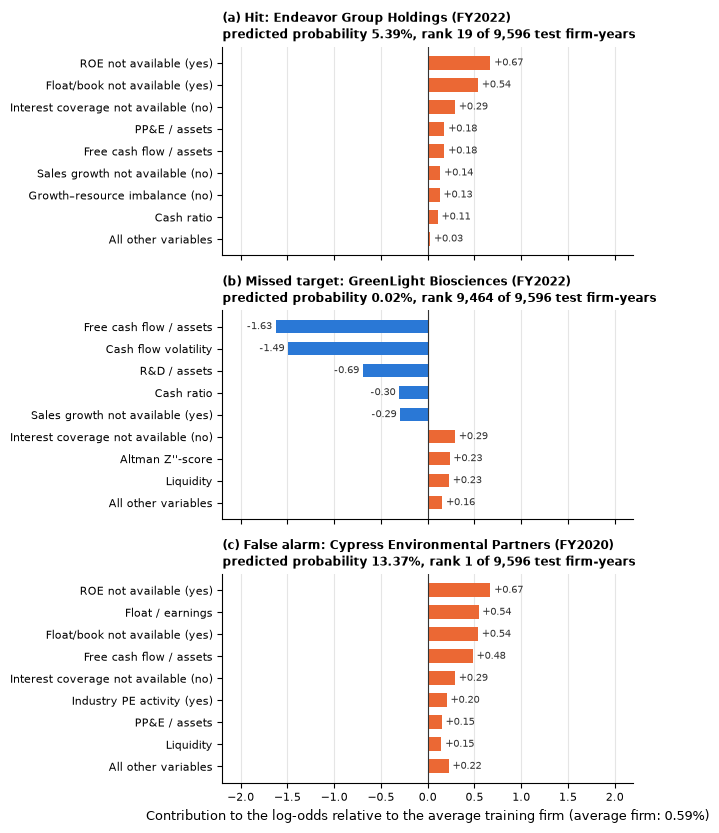

geschrieben: thesis_figures/fig4_5_case_contributions.png
geschrieben: thesis_tables/case_contributions.csv und .md (25 Zeilen)


In [19]:
CASE_LABELS = {"(a) Treffer": "(a) Hit", "(b) Verpasst": "(b) Missed target", "(c) Fehlalarm": "(c) False alarm"}
NICE_NAMES = {"1766363": "Endeavor Group Holdings", "1822691": "GreenLight Biosciences",
              "1587246": "Cypress Environmental Partners"}      # Firmennamen in normaler Schreibweise, je CIK
BINARY = [c for c in b_cols if c.endswith("_missing")] + ["grdummy", "idummy"]

def case_label(var, row):
    """Lesbarer Name; bei 0/1-Variablen zusätzlich der Wert der Firma, damit das Vorzeichen verständlich ist."""
    if var in BINARY:
        return f"{vlabel(var)} ({'yes' if row[var] == 1 else 'no'})"
    return vlabel(var)

for k, r in cases.items():                                     # Kontrolle: CIK-Zuordnung der Namen stimmt
    assert str(int(r["cik"])) in NICE_NAMES, r["company_name"]
n_te = len(te)
p_avg = 1 / (1 + np.exp(-base_logodds))
contrib_all = pd.DataFrame(case_contrib)
lim_x = contrib_all.abs().max().max() * 1.35

fig, axes = plt.subplots(3, 1, figsize=(6.5, 8.4), sharex=True)
for ax, (key, case_name) in zip(axes, CASE_LABELS.items()):
    row, contrib = cases[key], case_contrib[key]
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:8])
    top.index = [case_label(v, row) for v in top.index]
    s = pd.concat([top, pd.Series({"All other variables": contrib.drop(contrib.abs().sort_values(ascending=False).index[:8]).sum()})]).iloc[::-1]
    ax.barh(range(len(s)), s.to_numpy(), height=0.62, color=[C_ORANGE if v > 0 else C_BLUE for v in s], zorder=2)
    ax.set_yticks(range(len(s)), s.index, fontsize=8)
    ax.axvline(0, color=C_INK, linewidth=0.8, zorder=3)
    for i, v in enumerate(s.to_numpy()):
        ax.text(v + (0.04 if v >= 0 else -0.04), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right",
                fontsize=7, color=C_INK)
    ax.set_xlim(-lim_x, lim_x)
    ax.grid(axis="x", color=C_GRID, linewidth=0.8, zorder=1)
    ax.set_title(f"{case_name}: {NICE_NAMES[str(int(row['cik']))]} (FY{int(row['fiscal_year'])})\n"
                 f"predicted probability {row['p_hat']:.2%}, rank {int(row['Rang']):,} of {n_te:,} test firm-years",
                 loc="left", fontsize=8.5, fontweight="bold", linespacing=1.4)
axes[-1].set_xlabel(f"Contribution to the log-odds relative to the average training firm (average firm: {p_avg:.2%})")
fig.tight_layout()
save_fig(fig, "fig4_5_case_contributions.png")

case_tab = contrib_all.rename(columns=CASE_LABELS).reset_index().rename(columns={"index": "code"})
case_tab.insert(0, "variable", case_tab["code"].map(vlabel))
for k, r in cases.items():                                     # Wert der Firma je Variable (bei 0/1: yes/no)
    case_tab[f"{CASE_LABELS[k]}: value"] = [("yes" if r[c] == 1 else "no") if c in BINARY else round(float(r[c]), 4)
                                            for c in case_tab["code"]]
case_meta = [f"{CASE_LABELS[k]}: {NICE_NAMES[str(int(r['cik']))]} (CIK {r['cik']}), FY{int(r['fiscal_year'])}, predicted {r['p_hat']:.2%}, "
             f"rank {int(r['Rang']):,} of {n_te:,}" for k, r in cases.items()]
write_table(case_tab, "case_contributions", "Variable contributions for the three explained cases (Model B, test FY2020–2022)",
            case_meta + [f"Contribution = coefficient × (firm value − training mean), log-odds; starting point (average training firm) {p_avg:.2%}."],
            md_df=case_tab.drop(columns="code").round(3))

## Anhang: Watchlist Top 20

Aus 09: Watchlist-Modell (Spezifikation B2 auf FY2012–2022, Variablenliste wie B/B2), neuestes Firmenjahr FY2024/25, Firmen außerhalb des Event-Universums. „Later outcome“ fasst die nur lesende EDGAR-Prüfung zusammen. Die Einordnung von Apogee (Käufer AbbVie) stammt aus dem manuellen Lesen der DEFM14A (dokumentiert in `PROGRESS.md`) und ist deshalb als Anmerkung gekennzeichnet.

In [20]:
MANUAL_NOTES = {   # manuell gelesene Proxies (PROGRESS.md, 31.10.2026); nicht aus dem Code abgeleitet
    "Apogee Therapeutics": "Proxy read manually: acquired by AbbVie (merger agreement 18 Jun 2026), strategic buyer, not PE.",
}

def outcome_text(cik, hit_list):
    own = [h for h in hit_list if h["CIK"] == cik]
    if not own:
        return f"no matching filing after fiscal year-end (checked {checked_on.date()})"
    return "; ".join(f"{h['Formular']} {h['Datum']}: {to_english(h['Einordnung'])}" for h in own)

def to_english(text):
    """Einordnung aus 09 (deutsch) für die Arbeit übersetzen."""
    return (text.replace("Firma ist Zielgesellschaft", "firm is the subject company (target)")
                 .replace("Firma ist Bieter/Käufer, Ziel:", "firm is the bidder; target:")
                 .replace("manuell prüfen (Proxy kann auch von der Käuferseite stammen)", "merger proxy, needs manual reading")
                 .replace("manuell prüfen", "needs manual reading")
                 .replace("Delisting von:", "delisting of:"))

def watch_table(top, hit_list):
    t = pd.DataFrame({
        "rank": range(1, len(top) + 1), "firm": top["company_name"].to_numpy(), "CIK": top["cik"].to_numpy(),
        "fiscal year": top["fiscal_year"].astype(int).to_numpy(), "fiscal year-end": top["period_end"].to_numpy(),
        "predicted 3-year probability": top["p_hat"].to_numpy(), "partnership flag": top["is_partnership"].map({True: "yes", False: "no"}).to_numpy(),
        "later outcome (EDGAR check)": [outcome_text(c, hit_list) for c in top["cik"]],
    })
    t["PE take-private confirmed"] = [("yes" if any(h["CIK"] == c and h["Einordnung"] == "Firma ist Zielgesellschaft" and
                                                  h["Formular"].startswith(("SC 13E", "SCHEDULE 13E")) for h in hit_list) else "no")
                                      for c in t["CIK"]]
    t["note"] = [next((v for k, v in MANUAL_NOTES.items() if k.lower() in f.lower()), "") for f in t["firm"]]
    return t

watch_notes = ["Watch model: variant B2 specification re-estimated on all observed firm-years FY2012–2022 (same variable list as Model B/B2); applied to each firm's latest fiscal year (FY2024 or FY2025); firms already in the event universe (combined_events.csv) excluded.",
               "EDGAR check (read-only, data.sec.gov submissions): SC 13E3, DEFM14A, PREM14A, SC TO-T, 25-NSE (incl. /A and SCHEDULE spellings) filed after the fiscal year-end. Role check: subject company for SC TO-T/13E3, security class for 25-NSE; proxies need manual reading.",
               "'PE take-private confirmed' is 'no' for all firms: no filing shows the firm as the target of a PE buyer."]
wl = watch_table(top20, hits)
wl_md = wl.assign(**{"predicted 3-year probability": wl["predicted 3-year probability"].map("{:.2%}".format)})
write_table(wl, "appendix_watchlist_top20", "Watchlist: top 20 (all candidates)", watch_notes, md_df=wl_md)
wl_np = watch_table(top20_np, hits_np)
write_table(wl_np, "appendix_watchlist_top20_no_partnerships", "Watchlist: top 20 without partnerships", watch_notes,
            md_df=wl_np.assign(**{"predicted 3-year probability": wl_np["predicted 3-year probability"].map("{:.2%}".format)}))
print(f"Partnerships in der Top 20: {(wl['partnership flag'] == 'yes').sum()} | McFadden Watchlist-Modell {watch_model.prsquared:.2%}")
wl_md[["rank", "firm", "fiscal year", "predicted 3-year probability", "partnership flag", "later outcome (EDGAR check)"]]

geschrieben: thesis_tables/appendix_watchlist_top20.csv und .md (20 Zeilen)
geschrieben: thesis_tables/appendix_watchlist_top20_no_partnerships.csv und .md (20 Zeilen)
Partnerships in der Top 20: 13 | McFadden Watchlist-Modell 5.74%


,rank,firm,fiscal year,predicted 3-year probability,partnership flag,later outcome (EDGAR check)
0,1,WESTLAKE CHEMICAL PARTNERS LP,2024,9.01%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
1,2,"KIMBELL ROYALTY PARTNERS, LP",2024,7.97%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
2,3,CROSSAMERICA PARTNERS LP,2024,7.17%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
3,4,NEW ENGLAND REALTY ASSOCIATES LIMITED PARTNERSHIP,2024,5.85%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
4,5,SUBURBAN PROPANE PARTNERS LP,2025,5.01%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
5,6,"DELEK LOGISTICS PARTNERS, LP",2024,4.58%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
6,7,NGL ENERGY PARTNERS LP,2024,4.58%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
7,8,"STAR GROUP, L.P.",2025,4.48%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
8,9,NATURAL RESOURCE PARTNERS LP,2024,4.26%,yes,no matching filing after fiscal year-end (checked 2026-11-01)
9,10,MACH NATURAL RESOURCES LP,2024,4.01%,yes,no matching filing after fiscal year-end (checked 2026-11-01)


## Anhang: LLM-Validierung (Goldstandard, 30 Fälle)

Quelle: `data/interim/goldstandard_sample.csv` (31 gezogene Fälle; Vapor Corp ist laut `PROGRESS.md` ausgeschlossen, weil die verfolgte Meldung Vapor als Käufer zeigt). Das **Modell-Label** ist das finale `buyer_type` aus Stage 5–10 (Claude Haiku 4.5, `claude-haiku-4-5-20251001`, Prompt in `src/05_buyer_classification.py`).

**Die Handlabels je Fall sind nicht im Repository gespeichert**, nur die Konfusionsmatrix in `PROGRESS.md`. Für die 22 Fälle, in denen das Modell sich festlegt, folgt das Handlabel zwingend aus der Matrix (alle Festlegungen liegen auf der Diagonale: 22/22). Für die 8 übrigen Fälle (6 abstained, 2 `unknown`) kennt die Matrix nur die Summen; diese Zellen bleiben leer und müssen aus dem Kodierbogen des Autors ergänzt werden.

In [21]:
gs = pd.read_csv(Path("..") / "data" / "interim" / "goldstandard_sample.csv", dtype=str)
gs = gs[gs["cik"] != "0000844856"]            # Vapor Corp ausgeschlossen (PROGRESS.md, Goldstandard Validation)
assert len(gs) == 30
abst = gs["abstained"] == "True"
committed = ~abst & (gs["buyer_type"] != "unknown")
llm = pd.DataFrame({
    "deal (target)": gs["company_name"].to_numpy(), "CIK": gs["cik"].to_numpy(),
    "source": gs["source_type"].to_numpy(), "completion status": gs["completion_status"].to_numpy(),
    "model label": np.where(abst, "abstained", gs["buyer_type"]),
    "model buyer name": gs["buyer_name"].fillna("").to_numpy(),
    "abstain": np.where(abst, "yes", "no"),
    "hand label": np.where(committed, gs["buyer_type"], ""),
    "hand label source": np.where(committed, "implied by confusion matrix (22/22 on diagonal)", "not stored in repository – fill in from coding sheet"),
})
print(llm["model label"].value_counts().to_dict(), "| festgelegt:", int(committed.sum()))
write_table(llm, "appendix_llm_validation", "LLM buyer-type classification: goldstandard validation (30 cases)",
            ["Model: Claude Haiku 4.5 (claude-haiku-4-5-20251001), single pass, forced tool call with literal supporting quotes, mandatory abstain option (src/05_buyer_classification.py).",
             "Model label = final buyer_type after the Stage 6/7/9/10 evidence fixes (e.g. Golden Entertainment: family/Sartini after the regression fix).",
             "Hand labels per case are not stored in the repository. For the 22 committed cases the hand label follows from the confusion matrix in PROGRESS.md (all on the diagonal).",
             "For the 8 non-committed cases the matrix gives only totals: model 'abstained' (6) = hand family 2, strategic 2, unknown 2; model 'unknown' (2) = hand family 1, strategic 1.",
             "Excluded: Vapor Corp (CIK 0000844856), the tracked filing shows Vapor as the acquirer, not the target."])
llm[["deal (target)", "model label", "abstain", "hand label"]]

{'strategic': 9, 'pe_sponsor': 8, 'abstained': 6, 'family': 4, 'unknown': 2, 'management': 1} | festgelegt: 22
geschrieben: thesis_tables/appendix_llm_validation.csv und .md (30 Zeilen)


,deal (target),model label,abstain,hand label
0,FREDERICK'S OF HOLLYWOOD GROUP INC /NY/,pe_sponsor,no,pe_sponsor
1,"GOLDEN ENTERTAINMENT, INC.",family,no,family
2,RealD Inc.,pe_sponsor,no,pe_sponsor
3,"CRAFT BREW ALLIANCE, INC.",strategic,no,strategic
4,"Orchard Enterprises, Inc.",family,no,family
5,Sinoenergy CORP,management,no,management
6,"El Paso Pipeline Partners, L.P.",strategic,no,strategic
7,Ashford Inc.,abstained,yes,
8,STEIN MART INC,pe_sponsor,no,pe_sponsor
9,China XD Plastics Co Ltd,pe_sponsor,no,pe_sponsor


## Übersicht der erzeugten Dateien

In [22]:
for folder in (FIG, TAB):
    for f in sorted(folder.iterdir()):
        print(f"{folder.name}/{f.name}")

thesis_figures/fig4_1_positives_per_year.png
thesis_figures/fig4_2_size_effect_B2.png
thesis_figures/fig4_3_calibration.png
thesis_figures/fig4_4_shap_summary.png
thesis_figures/fig4_5_case_contributions.png
thesis_tables/appendix_coefficients.csv
thesis_tables/appendix_coefficients.md
thesis_tables/appendix_hyperparameters.csv
thesis_tables/appendix_hyperparameters.md
thesis_tables/appendix_llm_validation.csv
thesis_tables/appendix_llm_validation.md
thesis_tables/appendix_model_fit.csv
thesis_tables/appendix_model_fit.md
thesis_tables/appendix_robustness.csv
thesis_tables/appendix_robustness.md
thesis_tables/appendix_variable_definitions.csv
thesis_tables/appendix_variable_definitions.md
thesis_tables/appendix_watchlist_top20.csv
thesis_tables/appendix_watchlist_top20.md
thesis_tables/appendix_watchlist_top20_no_partnerships.csv
thesis_tables/appendix_watchlist_top20_no_partnerships.md
thesis_tables/calibration_bins.csv
thesis_tables/calibration_bins.md
thesis_tables/case_contribution